In [ ]:
import pandas as pd

tsne_df = pd.read_csv('../G2CP/results/LINCS_cause_space.csv')

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.font_manager import FontProperties, fontManager
from matplotlib.ticker import FuncFormatter
import matplotlib.colors as mcolors

sns.set_theme(style="ticks", rc={"axes.facecolor": (0, 0, 0, 0)}, font_scale=1.2)
font_path = '../Helvetica.ttf' 
fontManager.addfont(font_path)
prop = FontProperties(fname=font_path)
font_name = prop.get_name()
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = [font_name] 
print("Current font settings:", plt.rcParams['font.sans-serif'])

Current font settings: ['Helvetica']


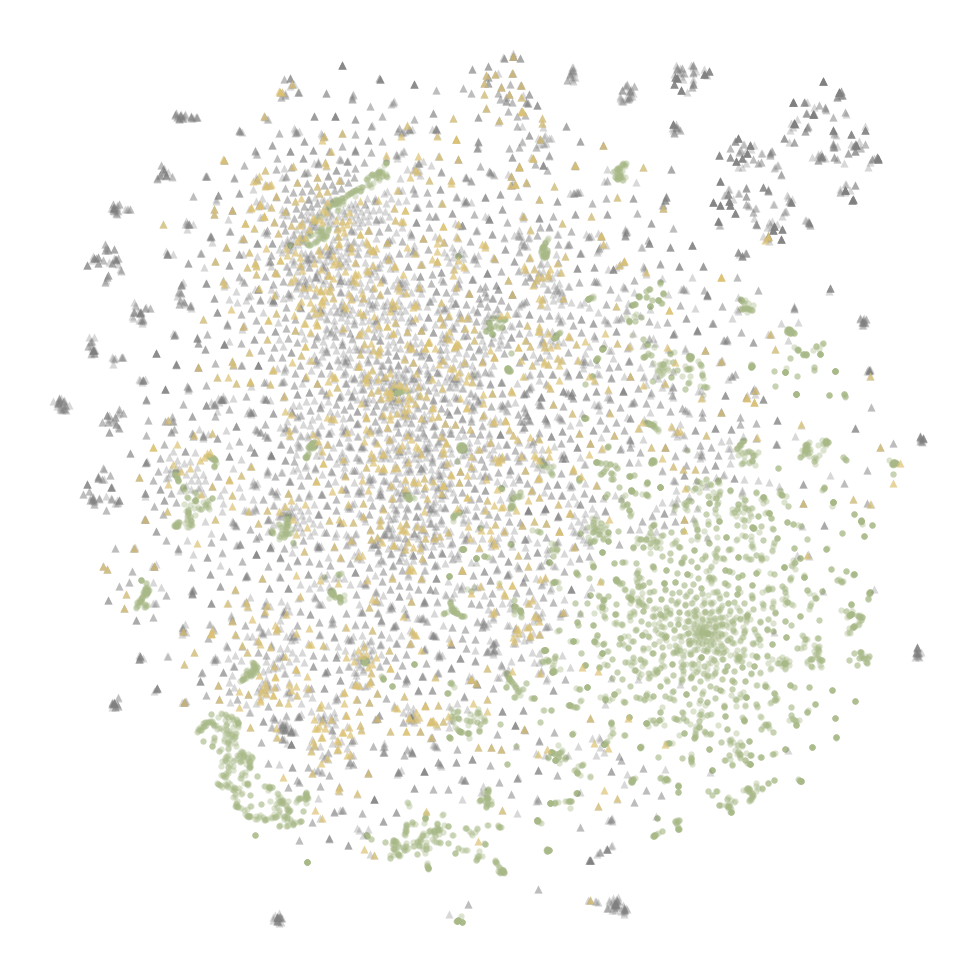

In [57]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 10))

angle = -50
angle_rad = np.deg2rad(angle)
rotation_matrix = np.array([[np.cos(angle_rad), -np.sin(angle_rad)],
                            [np.sin(angle_rad), np.cos(angle_rad)]])
tsne_df[['rot_tsne1', 'rot_tsne2']] = tsne_df[['tsne1', 'tsne2']].dot(rotation_matrix)

plt.scatter(tsne_df[tsne_df['Guide/Touchstone/Discover'] == 'Guide']['rot_tsne1'], 
            tsne_df[tsne_df['Guide/Touchstone/Discover'] == 'Guide']['rot_tsne2'], 
            marker='o', color='#a8b987', alpha=0.4, s=20, linewidths=0, label='Guide (5,002)')  # 灰色实心圆


plt.scatter(tsne_df[tsne_df['Guide/Touchstone/Discover'] == 'Discover']['rot_tsne1'], 
            tsne_df[tsne_df['Guide/Touchstone/Discover'] == 'Discover']['rot_tsne2'], 
            marker='^', color='gray', alpha=0.3, s=34, linewidths=0, label='Discover (6,800)')  # 灰色实心三角形

plt.scatter(tsne_df[tsne_df['Guide/Touchstone/Discover'] == 'Touchstone']['rot_tsne1'], 
            tsne_df[tsne_df['Guide/Touchstone/Discover'] == 'Touchstone']['rot_tsne2'], 
            marker='^', color='#dcc273', alpha=0.7, s=34, linewidths=0, label='Touchstone (1,021)')  # 黄色实心三角形

plt.axis('off')
plt.tight_layout()
plt.show()

In [58]:
tsne_df['PharmGKB pathway'] = tsne_df['PharmGKB pathway'].str.split(';')
tsne_df = tsne_df.explode('PharmGKB pathway')

In [64]:
categories = [
    "PA2032-VEGF_Signaling_Pathway",
    "PA165948566-Metformin_Pathway_Pharmacodynamics",
    "PA161749006-Selective_Serotonin_Reuptake_Inhibitor_Pathway_Pharmacodynamics",
    "PA165980050-Vemurafenib_Pathway_Pharmacodynamics",
    "PA166121942-Ibuprofen_Pathway_Pharmacodynamics",
    "PA2042-Sympathetic_Nerve_Pathway_Neuroeffector_Junction",
    "PA165959584-Sorafenib_Pharmacodynamics",
    "PA165986279-Acetaminophen_Pathway_therapeutic_doses_Pharmacokinetics",
    "PA165817070-Carbamazepine_Pathway_Pharmacokinetics",
    "PA165860384-Lamivudine_Pathway_Pharmacokinetics_Pharmacodynamics",
    "PA165959313-Valproic_Acid_Pathway_Pharmacodynamics",
    "PA166041114-Ibuprofen_Pathway_Pharmacokinetics"
]

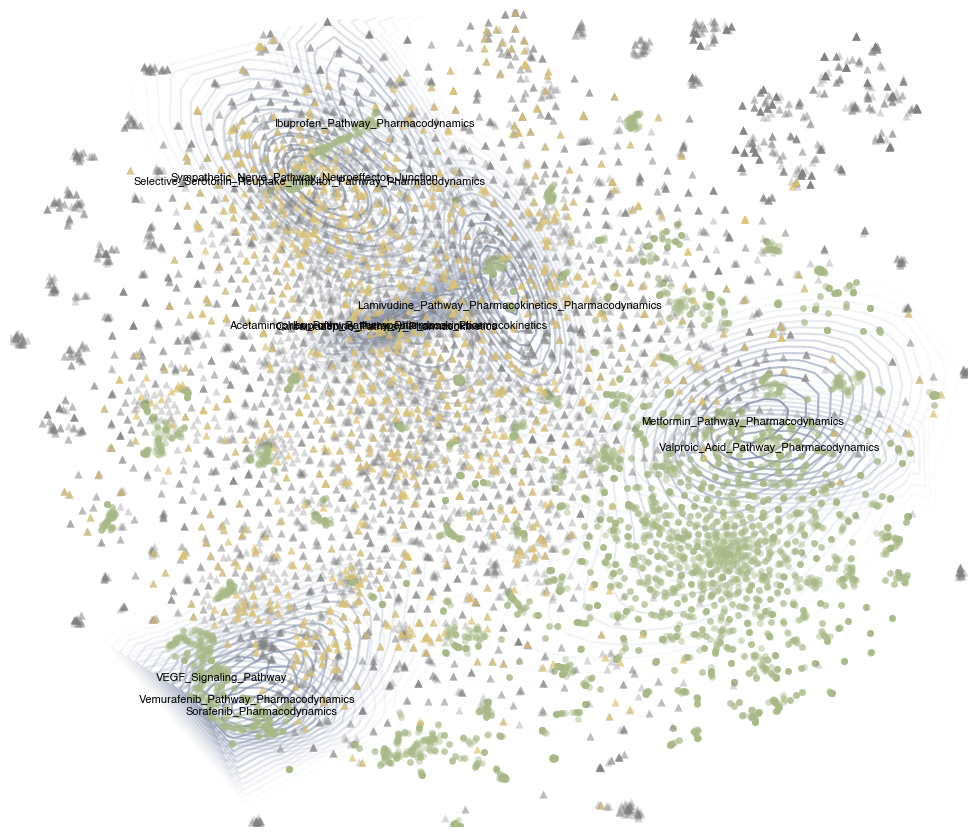

In [ ]:
import matplotlib.pyplot as plt 
import numpy as np 
from scipy.stats import gaussian_kde 

fig, ax = plt.subplots(figsize=(10, 8.6))

angle = -50
angle_rad = np.deg2rad(angle)
rotation_matrix = np.array([[np.cos(angle_rad), -np.sin(angle_rad)],
                            [np.sin(angle_rad), np.cos(angle_rad)]])
tsne_df[['rot_tsne1', 'rot_tsne2']] = tsne_df[['tsne1', 'tsne2']].dot(rotation_matrix)
x = tsne_df['rot_tsne1']
y = tsne_df['rot_tsne2']

cmap = mcolors.LinearSegmentedColormap.from_list("custom_cmap", ["w", "#7180A2"])
for j, category in enumerate(categories):
    category_data = tsne_df[tsne_df['PharmGKB pathway'] == category]
    if not category_data.empty:
        kde = gaussian_kde(np.vstack([category_data['rot_tsne1'], category_data['rot_tsne2']]))
        z = kde(np.vstack([x, y])) 
        contour = ax.tricontour(x, y, z, levels=20, cmap=cmap, zorder=0)
        peak_idx = np.argmax(
            kde(np.vstack([
                category_data['rot_tsne1'],
                category_data['rot_tsne2']
            ]))
        )

        peak_x = category_data['rot_tsne1'].iloc[peak_idx]
        peak_y = category_data['rot_tsne2'].iloc[peak_idx]
        ax.text(
            peak_x,
            peak_y,
            category.split('-')[-1],
            fontsize=8,
            ha='center',
            va='center',
            weight='bold',
            color='black',
            zorder=20
        )
        for i, collection in enumerate(contour.collections):
            alpha = max(0, i/20-0.2) 
            collection.set_alpha(alpha)

ax.scatter(tsne_df[tsne_df['Guide/Touchstone/Discover'] == 'Guide']['rot_tsne1'], 
            tsne_df[tsne_df['Guide/Touchstone/Discover'] == 'Guide']['rot_tsne2'], 
            marker='o', color='#a8b987', alpha=0.45, s=24, linewidths=0, zorder=10) 


ax.scatter(tsne_df[tsne_df['Guide/Touchstone/Discover'] == 'Discover']['rot_tsne1'], 
            tsne_df[tsne_df['Guide/Touchstone/Discover'] == 'Discover']['rot_tsne2'], 
            marker='^', color='gray', alpha=0.3, s=34, linewidths=0, zorder=10) 

ax.scatter(tsne_df[tsne_df['Guide/Touchstone/Discover'] == 'Touchstone']['rot_tsne1'], 
            tsne_df[tsne_df['Guide/Touchstone/Discover'] == 'Touchstone']['rot_tsne2'], 
            marker='^', color='#dcc273', alpha=0.7, s=34, linewidths=0, zorder=10) 


plt.axis('off')
plt.tight_layout()
plt.show()